# Dinosaur: 3-D conditional Kinematic Interpolant on LAGRANTO parcel tracks

Explicit, ocean-notebook-style walk through the conditional KI (`ki/notebooks/oceans_currents_interpolant.ipynb` is the template), in three dimensions. The acceleration a(t, x, v) and velocity score of the paper are predicted from the state of a parcel *and* the observed tracks of the other parcels of its patch (a Perceiver encoder over those tracks, cross-attention from the query state). Two tasks: forecast (the patch was observed for the 48 h before the anchor time) and backcast (observed for the 48 h after it); in both, every parcel is unobserved on the other side, and the target parcels are not in the context. State: polar-stereographic x, y and log-pressure height z. Data: 3-D LAGRANTO tracks in 56 baroclinic life cycles of the Dinosaur primitive-equation core (THM93 set-up, 15 sigma levels), 48 used for training and 8 unseen (4 inside, 4 outside the training ranges of jet speed, basic-state type, wavenumber and amplitude); patches start at 5 levels from the surface layer to about 240 hPa. By default the notebook loads the model trained with DDP by `scripts/20_train_context.py`; set `TRAIN = True` to train here.

## 1. Imports

In [1]:
from pathlib import Path
from copy import deepcopy
import json, math, sys
import numpy as np
import pandas as pd
import torch
from torch import nn
import xarray as xr
import matplotlib.pyplot as plt
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'scripts/ctx_model.py').is_file() and (p / 'PLAN.md').is_file())

## 2. Editable hyperparameters

In [2]:
CONFIG = json.loads((ROOT / 'configs/flows.json').read_text())
FLOWS = [f for f in (CONFIG['flows'] if isinstance(CONFIG, dict) else CONFIG) if f.get('status', 'ok') == 'ok']
WINDOWS = [0, 1]
LEVELS = [0, 1, 2, 3, 4]
H_KM = 7.0
MODEL = ROOT / 'outputs/models/context_ki_3d.pt'
TRAIN = False      # True: train here (single GPU)
TRAIN_STEPS = 60000
BATCH = 32
CONTEXT_PARCELS = 192
QUERIES = 256
SPAN_H = 48
HORIZON_H = 24
LR = 3e-4
EMA_DECAY = 0.999
EVAL_WINDOWS = [0]
EVAL_ANCHORS_H = [72]
HORIZONS_H = [6, 12, 24]
DEVICE = 'cuda'

## 3. The flows
Basic-state type, jet speed, mode wavenumber and amplitude of the 56 life cycles; left: eddy kinetic energy at the lowest model level against time (training grey, unseen coloured); right: omega near 850 hPa (sigma 0.887) on day 7 for a training and an unseen flow.

In [3]:
pd.DataFrame(FLOWS)[[c for c in ('name', 'case', 'z2', 'ujet', 'm', 'amp', 'split', 'label') if c in FLOWS[0]]]

,name,case,z2,ujet,m,amp,split,label
0,t01_lc1_u35_m5_a05,lc1,none,35.0,5,0.5,train,training
1,t02_lc1_u40_m5_a05,lc1,none,40.0,5,0.5,train,training
2,t03_lc1_u40_m7_a2,lc1,none,40.0,7,2.0,train,training
3,t04_lc1_u45_m7_a05,lc1,none,45.0,7,0.5,train,training
4,t05_lc1_u50_m6_a1,lc1,none,50.0,6,1.0,train,training
5,t06_lc1_u50_m7_a05,lc1,none,50.0,7,0.5,train,training
6,t07_lc1_u55_m4_a2,lc1,none,55.0,4,2.0,train,training
7,t08_lc1_u55_m6_a05,lc1,none,55.0,6,0.5,train,training
8,t09_lc1_u60_m5_a1,lc1,none,60.0,5,1.0,train,training
9,t10_lc2lobes_u35_m7_a05,lc2,lobes,35.0,7,0.5,train,training


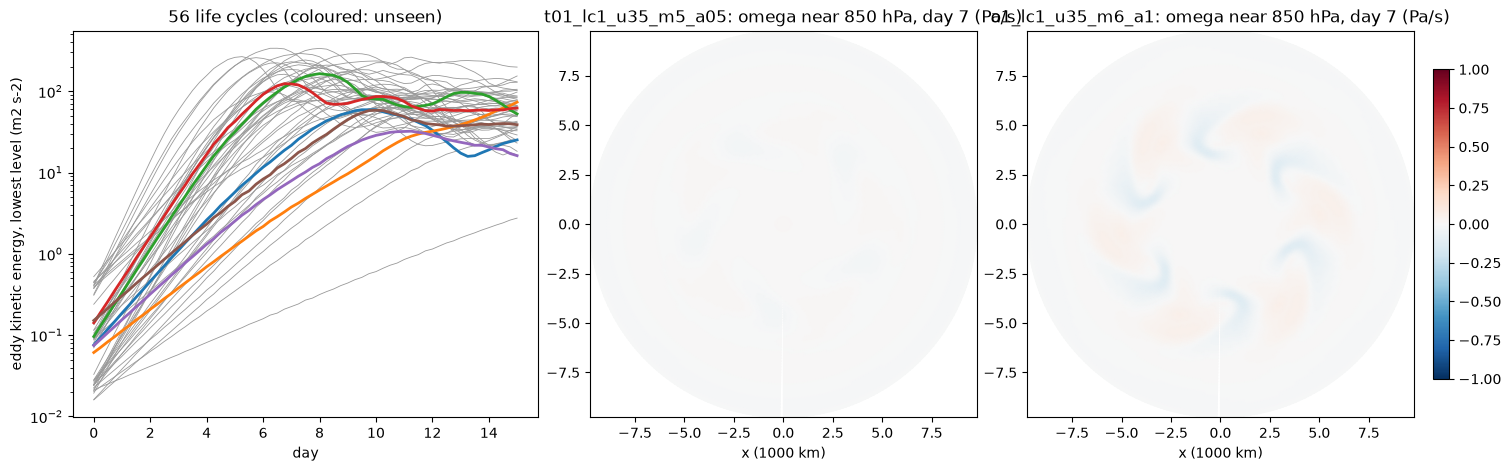

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6), layout='constrained', gridspec_kw=dict(width_ratios=[1.2, 1, 1]))
for f in FLOWS:
    ds = xr.open_dataset(ROOT / f"data/dino_{f['name']}.nc")
    u = ds.u.isel(level=-1, time=slice(None, None, 6)); v = ds.v.isel(level=-1, time=slice(None, None, 6))
    eke = 0.5 * ((u - u.mean('lon')) ** 2 + (v - v.mean('lon')) ** 2).sel(lat=slice(20, 80)).mean(('lat', 'lon'))
    ax[0].semilogy(np.arange(eke.size) / 4, eke, lw=0.6 if f['split'] == 'train' else 2, color='0.6' if f['split'] == 'train' else None)
ax[0].set(xlabel='day', ylabel='eddy kinetic energy, lowest level (m2 s-2)', title='56 life cycles (coloured: unseen)')
train0 = next(f['name'] for f in FLOWS if f['split'] == 'train'); test0 = next(f['name'] for f in FLOWS if f['split'] == 'test')
for a_, name in zip(ax[1:], [train0, test0]):
    w = xr.open_dataset(ROOT / f'data/dino_{name}.nc').omega.sel(level=0.887, method='nearest').isel(time=168).sel(lat=slice(15, 90))
    LON, LAT = np.meshgrid(w.lon, w.lat); r = 2 * 6371 * np.tan(np.deg2rad(90 - LAT) / 2) / 1e3
    pc = a_.pcolormesh(r * np.sin(np.deg2rad(LON)), -r * np.cos(np.deg2rad(LON)), w, cmap='RdBu_r', vmin=-1, vmax=1, shading='gouraud')
    a_.set_aspect('equal'); a_.set(title=f'{name}: omega near 850 hPa, day 7 (Pa/s)', xlabel='x (1000 km)')
fig.colorbar(pc, ax=ax[2], shrink=0.8)
plt.show()

## 4. Context model
Fourier features of the token and query coordinates, a Perceiver encoder (64 latents) over the context tokens, and a cross-attention decoder that returns the acceleration and the scaled velocity score of a query state. Everything is in normalized units relative to the anchor time and the patch centroid.

In [5]:
POS = (1000.0, 1000.0, 10.0)


VEL = (100.0, 100.0, 0.05)


ACC = (10.0, 10.0, 0.005)


TIME_H = 24.0


N_FEAT = 8


class Fourier(nn.Module):
    """Raw features plus sin/cos of the first `n_fourier` features at octave frequencies."""

    def __init__(self, n_in, n_fourier, octaves=6):
        super().__init__()
        self.n_fourier = n_fourier
        self.register_buffer("freqs", math.pi * 2.0 ** torch.arange(octaves, dtype=torch.float32))
        self.n_out = n_in + 2 * n_fourier * octaves

    def forward(self, z):
        f = z[..., : self.n_fourier, None] * self.freqs
        return torch.cat([z, torch.sin(f).flatten(-2), torch.cos(f).flatten(-2)], dim=-1)


class Block(nn.Module):
    """Pre-norm attention block (cross-attention when a context is given) with an MLP."""

    def __init__(self, d, heads, cross=False):
        super().__init__()
        self.nq = nn.LayerNorm(d)
        self.nk = nn.LayerNorm(d) if cross else None
        self.attn = nn.MultiheadAttention(d, heads, batch_first=True)
        self.mlp = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, q, kv=None, pad=None):
        h = self.nq(q)
        k = h if kv is None else self.nk(kv)
        q = q + self.attn(h, k, k, key_padding_mask=pad, need_weights=False)[0]
        return q + self.mlp(q)


def embed(n_in, n_fourier, d):
    f = Fourier(n_in, n_fourier)
    return nn.Sequential(f, nn.Linear(f.n_out, d), nn.GELU(), nn.Linear(d, d))


class ContextKI(nn.Module):
    """Perceiver encoder over context tokens and a cross-attention decoder for query states.

    Token features: (tau, x, y, z, sin lat, u, v, w); query features: the same for the state to be advanced.
    """

    def __init__(self, d=384, heads=8, latents=96, enc_layers=6, dec_layers=3):
        super().__init__()
        self.tok, self.qry = embed(N_FEAT, 4, d), embed(N_FEAT, 4, d)
        self.latents = nn.Parameter(torch.randn(latents, d) * 0.02)
        self.read = Block(d, heads, cross=True)
        self.enc = nn.ModuleList([Block(d, heads) for _ in range(enc_layers)])
        self.dec = nn.ModuleList([Block(d, heads, cross=True) for _ in range(dec_layers)])
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 6))
        nn.init.zeros_(self.head[1].weight)
        nn.init.zeros_(self.head[1].bias)

    def encode(self, tokens, pad=None):
        """tokens (B, M, 8), pad (B, M) True where absent -> latents (B, L, d)."""
        z = self.latents.expand(tokens.shape[0], -1, -1)
        z = self.read(z, self.tok(tokens), pad)
        for blk in self.enc:
            z = blk(z)
        return z

    def decode(self, z, queries):
        """queries (B, Q, 8) -> acceleration (B, Q, 3) and scaled score (B, Q, 3)."""
        h = self.qry(queries)
        for blk in self.dec:
            h = blk(h, z)
        out = self.head(h)
        return out[..., :3], out[..., 3:]

    def forward(self, tokens, pad, queries):
        return self.decode(self.encode(tokens, pad), queries)

## 5. Minibatches and rollouts
A sample is a patch, an anchor time and a direction. Context: 128 parcels of the patch, every 3 h over the 48 h on the observed side. Queries: parcels on and around their true tracks within 24 h on the unobserved side (the paper's rotating Gaussian noise; the target acceleration includes its restoring term). Rollouts integrate x' = v, v' = a forward (forecast) or backward (backcast) from the anchor.

In [6]:
from types import SimpleNamespace


OMEGA = np.pi * np.sqrt(3)


A_KM = 6371.0


def flow_names(config, split):
    return [f["name"] for f in read_flows(config) if f["split"] == split]


def read_flows(config):
    """Usable flows of the configuration (a list, or a dict with key "flows"); status must be "ok" if present."""
    flows = json.loads(Path(config).read_text())
    flows = flows["flows"] if isinstance(flows, dict) else flows
    return [f for f in flows if f.get("status", "ok") == "ok"]


def load_patches(root, names, windows, levels, patch_ids, n_per=1000, device="cuda", seed=0):
    """Stack patches of data/tracks_<flow>_w<k>_l<level>.npz into (Np, T, n_per, ...) GPU tensors."""
    rng = np.random.default_rng(seed)
    X, V, A, S, P, meta = [], [], [], [], [], []
    for name in names:
        for w in windows:
            for lev in levels:
                with np.load(Path(root) / f"data/tracks_{name}_w{w}_l{lev}.npz") as f:
                    x, v, a, lat, p, patch = f["x_km"], f["v_kmh"], f["a_kmh2"], f["lat"], f["p_hpa"], f["patch"]
                    t = f["time_h"]
                for q in patch_ids:
                    idx = np.where(patch == q)[0]
                    if len(idx) == 0:
                        continue
                    idx = idx if len(idx) == n_per else rng.choice(idx, n_per, replace=len(idx) < n_per)
                    X.append(x[:, idx])
                    V.append(v[:, idx])
                    A.append(a[:, idx])
                    S.append(np.sin(np.deg2rad(lat[:, idx])))
                    P.append(p[:, idx])
                    meta.append((name, w, lev, int(q)))
    to = lambda z: torch.tensor(np.stack(z), dtype=torch.float32, device=device)
    return SimpleNamespace(X=to(X), V=to(V), A=to(A), S=to(S), P=to(P), meta=meta, time_h=t)


def _scale(dev):
    return tuple(torch.tensor(s, dtype=torch.float32, device=dev) for s in (POS, VEL, ACC))


def context(D, p, t0, direction, kidx, span_h=48, step_h=3):
    """Context tokens (B, Tc*K, 8) and the horizontal patch centroid at t0 (B, 2)."""
    pos, vel, _ = _scale(D.X.device)
    offs = torch.arange(0, span_h + 1, step_h, device=D.X.device)
    tc = t0[:, None] - direction[:, None] * offs[None]
    ix = (p[:, None, None], tc[:, :, None], kidx[:, None, :])
    centroid = D.X[p, t0, :, :2].mean(1)
    x = D.X[ix]
    x = torch.cat([x[..., :2] - centroid[:, None, None], x[..., 2:]], -1)
    tau = ((tc - t0[:, None]).float() / TIME_H)[:, :, None, None].expand(-1, -1, kidx.shape[1], 1)
    tok = torch.cat([tau, x / pos, D.S[ix][..., None], D.V[ix] / vel], -1)
    return tok.flatten(1, 2), centroid


def sample_batch(D, B, K=192, Q=256, span_h=48, horizon_h=24, sx_km=(5.0, 5.0, 0.01), delta_h=6.0, gen=None):
    """One minibatch: context tokens, query states around true tracks, target accelerations and scores."""
    dev, (Np, T, N) = D.X.device, D.X.shape[:3]
    pos, vel, acc = _scale(dev)
    sx = torch.tensor(sx_km, dtype=torch.float32, device=dev)
    r = lambda *s: torch.rand(*s, device=dev, generator=gen)
    p = (r(B) * Np).long()
    direction = (r(B) < 0.5).long() * 2 - 1
    lo = torch.where(direction > 0, span_h, horizon_h)
    hi = torch.where(direction > 0, T - 1 - horizon_h, T - 1 - span_h)
    t0 = lo + (r(B) * (hi - lo + 1)).long()
    kidx = r(B, N).argsort(1)[:, :K]
    tok, centroid = context(D, p, t0, direction, kidx, span_h)
    qi = (r(B, Q) * N).long()
    qt = t0[:, None] + direction[:, None] * (1 + (r(B, Q) * horizon_h).long())
    ix = (p[:, None], qt, qi)
    th = r(B, Q, 1) * 2 * np.pi
    z1, z2 = torch.randn(2, B, Q, 3, device=dev, generator=gen)
    par, perp = torch.cos(th) * z1 + torch.sin(th) * z2, -torch.sin(th) * z1 + torch.cos(th) * z2
    w = OMEGA / delta_h
    xq, vq = D.X[ix] + sx * par, D.V[ix] + sx * w * perp
    aq = D.A[ix] - sx * w**2 * par
    xq = torch.cat([xq[..., :2] - centroid[:, None], xq[..., 2:]], -1)
    tau = ((qt - t0[:, None]).float() / TIME_H)[..., None]
    qry = torch.cat([tau, xq / pos, D.S[ix][..., None], vq / vel], -1)
    return tok, qry, (aq / acc).clamp(-ACC_CLIP, ACC_CLIP), -perp


def sin_lat(x_km):
    r = torch.hypot(x_km[..., 0], x_km[..., 1])
    return torch.cos(2 * torch.atan(r / (2 * A_KM)))


@torch.no_grad()
def rollout(model, tok, centroid, x0, v0, direction, horizon_h=24, steps_per_h=6):
    """Integrate x' = v, v' = a(tau, x, v | context) from tau = 0 (Heun); direction (B,) +1 forward, -1 backward.

    x0, v0: (B, Q, 3) in km and km/h (x, y, z). Returns hourly positions (horizon_h + 1, B, Q, 3) in km.
    """
    pos, vel, acc = _scale(x0.device)
    z = model.encode(tok)
    dt = direction.float()[:, None, None] / steps_per_h

    def accel(tau, x, v):
        rel = torch.cat([x[..., :2] - centroid[:, None], x[..., 2:]], -1)
        q = torch.cat([tau / TIME_H, rel / pos, sin_lat(x)[..., None], v / vel], -1)
        return model.decode(z, q)[0] * acc

    x, v, out = x0.clone(), v0.clone(), [x0.clone()]
    for s in range(horizon_h * steps_per_h):
        tau = (s * dt).expand(-1, x.shape[1], 1)
        a0 = accel(tau, x, v)
        xp, vp = x + dt * v, v + dt * a0
        x, v = x + 0.5 * dt * (v + vp), v + 0.5 * dt * (a0 + accel(tau + dt, xp, vp))
        if (s + 1) % steps_per_h == 0:
            out.append(x.clone())
    return torch.stack(out)

## 6. Training
AdamW, warm-up and cosine decay, EMA weights. The released model was trained with `torchrun --nproc-per-node 2 scripts/20_train_context.py` (DDP); its history is plotted below.

trained on 2 GPUs; best step 40000


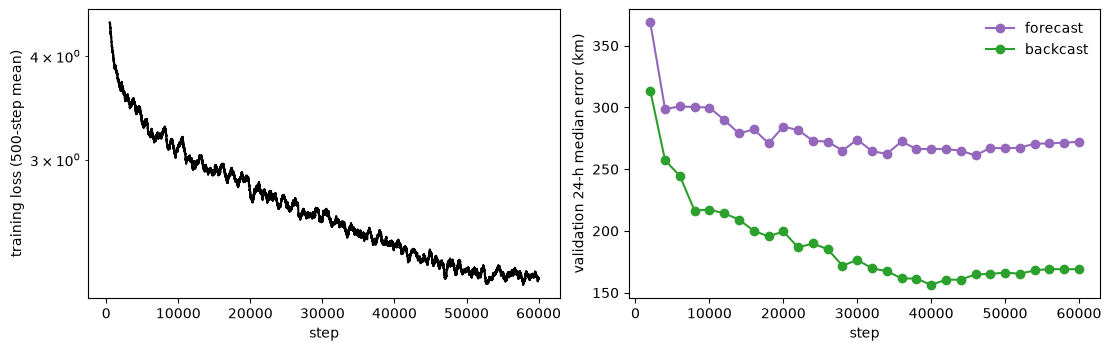

In [7]:
if TRAIN:
    train = load_patches(ROOT, flow_names(ROOT / 'configs/flows.json', 'train'), WINDOWS, LEVELS, range(6), device=DEVICE)
    model = ContextKI().to(DEVICE); ema = deepcopy(model).requires_grad_(False)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / 1000) * 0.5 * (1 + math.cos(math.pi * s / TRAIN_STEPS)))
    gen = torch.Generator(device=DEVICE).manual_seed(0)
    for step in range(1, TRAIN_STEPS + 1):
        tok, qry, acc, score = sample_batch(train, BATCH, CONTEXT_PARCELS, QUERIES, SPAN_H, HORIZON_H, gen=gen)
        a_hat, s_hat = model(tok, None, qry)
        loss = ((a_hat - acc) ** 2).mean() + ((s_hat - score) ** 2).mean()
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        with torch.no_grad():
            for e, w in zip(ema.parameters(), model.parameters()):
                e.lerp_(w, 1 - EMA_DECAY)
        if step % 2000 == 0:
            print(step, loss.item(), flush=True)
    model = ema.eval()
else:
    ck = torch.load(MODEL, map_location=DEVICE, weights_only=False)
    model = ContextKI(d=ck['args']['d_model']).to(DEVICE).eval(); model.load_state_dict(ck['state'])
    hist = json.loads((MODEL.parent / (MODEL.stem + '_history.json')).read_text())
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), layout='constrained')
    tr = np.asarray(hist['train']); k = 500
    ax[0].semilogy(hist['step'][k - 1:], np.convolve(tr, np.ones(k) / k, 'valid'), color='k'); ax[0].set(xlabel='step', ylabel=f'training loss ({k}-step mean)')
    ax[1].plot(hist['val_step'], hist['forecast_km'], 'o-', color='tab:purple', label='forecast')
    ax[1].plot(hist['val_step'], hist['backcast_km'], 'o-', color='tab:green', label='backcast')
    ax[1].set(xlabel='step', ylabel='validation 24-h median error (km)'); ax[1].legend(frameon=False)
    print('trained on', hist['world_size'], 'GPUs; best step', ck['step']); plt.show()

## 7. Conditional forecast and backcast on unseen patches and unseen flows
Targets are 128 parcels that are not in the context. `no learning` is straight motion at the anchor velocity.

In [8]:
def stereo_to_lonlat(x_km):
    """Inverse north-polar stereographic projection (tangent at the pole) -> lon, lat in degrees."""
    r = np.hypot(x_km[..., 0], x_km[..., 1])
    lat = 90.0 - np.rad2deg(2 * np.arctan(r / (2 * 6371.0)))
    lon = np.rad2deg(np.arctan2(x_km[..., 0], -x_km[..., 1])) % 360.0
    return lon, lat


def great_circle_km(lon1, lat1, lon2, lat2):
    p1, p2, dl = np.deg2rad(lat1), np.deg2rad(lat2), np.deg2rad(lon2 - lon1)
    c = np.sin(p1) * np.sin(p2) + np.cos(p1) * np.cos(p2) * np.cos(dl)
    return 6371.0 * np.arccos(np.clip(c, -1.0, 1.0))


class Straight(nn.Module):
    def encode(self, tok):
        return None

    def decode(self, z, q):
        return torch.zeros_like(q[..., 1:4]), None


cases = [('trained flows, unseen patches', [f['name'] for f in FLOWS if f['split'] == 'train'], [7])]
cases += [(f'unseen, {k} the training ranges', [f['name'] for f in FLOWS if f['split'] == 'test' and k in f.get('label', '')], list(range(8))) for k in ('inside', 'outside')]
rows, examples = [], {}
for label, names, patches in cases:
    D = load_patches(ROOT, names, EVAL_WINDOWS, LEVELS, patches, device=DEVICE)
    gen = torch.Generator(device=DEVICE).manual_seed(7)
    pp, dd, tt = (torch.tensor(z, device=DEVICE).flatten() for z in np.meshgrid(np.arange(D.X.shape[0]), [1, -1], EVAL_ANCHORS_H, indexing='ij'))
    perm = torch.rand(len(pp), D.X.shape[2], device=DEVICE, generator=gen).argsort(1)
    kidx, qidx = perm[:, :CONTEXT_PARCELS], perm[:, CONTEXT_PARCELS:CONTEXT_PARCELS + 128]
    tok, cen = context(D, pp, tt, dd, kidx, SPAN_H)
    x0, v0 = D.X[pp[:, None], tt[:, None], qidx], D.V[pp[:, None], tt[:, None], qidx]
    steps = tt[:, None] + dd[:, None] * torch.arange(HORIZON_H + 1, device=DEVICE)
    truth = D.X[pp[:, None, None], steps[:, :, None], qidx[:, None]].transpose(0, 1).cpu().numpy()
    for mlabel, m in (('conditional KI', model), ('no learning', Straight())):
        path = rollout(m, tok, cen, x0, v0, dd, HORIZON_H).cpu().numpy()
        examples[(label, mlabel)] = (tok.cpu(), cen.cpu(), path, truth, dd.cpu().numpy())
        for h in HORIZONS_H:
            (lp, ap), (lt, at) = stereo_to_lonlat(path[h][..., :2]), stereo_to_lonlat(truth[h][..., :2])
            err = great_circle_km(lp, ap, lt, at)
            dp = np.abs(1000 * (np.exp(-path[h][..., 2] / H_KM) - np.exp(-truth[h][..., 2] / H_KM)))
            for task, sel in (('forecast', dd.cpu().numpy() > 0), ('backcast', dd.cpu().numpy() < 0)):
                rows.append(dict(case=label, task=task, horizon_h=h, model=mlabel, median_km=float(np.median(err[sel])), median_hpa=float(np.median(dp[sel]))))
summary = pd.DataFrame(rows)
summary.pivot_table(index=['task', 'horizon_h'], columns=['case', 'model'], values=['median_km', 'median_hpa']).round(0)

median_hpa              \
case               trained flows, unseen patches               
model                             conditional KI no learning   
task     horizon_h                                             
backcast 6                                   2.0         2.0   
         12                                  3.0         6.0   
         24                                  5.0        17.0   
forecast 6                                   2.0         2.0   
         12                                  4.0         8.0   
         24                                 10.0        25.0   

                                                                   \
case               unseen, inside the training ranges               
model                                  conditional KI no learning   
task     horizon_h                                                  
backcast 6                                        1.0         2.0   
         12                                       1.0         4.0   
         24                                       3.0         8.0   
forecast 6                                        1.0         2.0   
         12                                       2.0         5.0   
         24                                       4.0        12.0   

                                                                    \
case               unseen, outside the training ranges               
model                                   conditional KI no learning   
task     horizon_h                                                   
backcast 6                                         1.0         1.0   
         12                                        1.0         2.0   
         24                                        2.0         5.0   
forecast 6                                         1.0         1.0   
         12                                        1.0         2.0   
         24                                        3.0         6.0   

                                       median_km              \
case               trained flows, unseen patches               
model                             conditional KI no learning   
task     horizon_h                                             
backcast 6                                  18.0        34.0   
         12                                 55.0       114.0   
         24                                184.0       391.0   
forecast 6                                  18.0        36.0   
         12                                 68.0       140.0   
         24                                261.0       548.0   

                                                                   \
case               unseen, inside the training ranges               
model                                  conditional KI no learning   
task     horizon_h                                                  
backcast 6                                       11.0        19.0   
         12                                      32.0        62.0   
         24                                     100.0       220.0   
forecast 6                                       11.0        18.0   
         12                                      38.0        71.0   
         24                                     143.0       302.0   

                                                                    
case               unseen, outside the training ranges              
model                                   conditional KI no learning  
task     horizon_h                                                  
backcast 6                                         8.0        10.0  
         12                                       23.0        29.0  
         24                                       75.0       102.0  
forecast 6                                         8.0         9.0  
         12                                       26.0        31.0  
         24                                       86

## 8. Visualize
One forecast and one backcast from an unseen patch of a training flow (top) and of the flow furthest from training (bottom): context tracks grey, model red dashed, truth blue, black dots = anchor states.

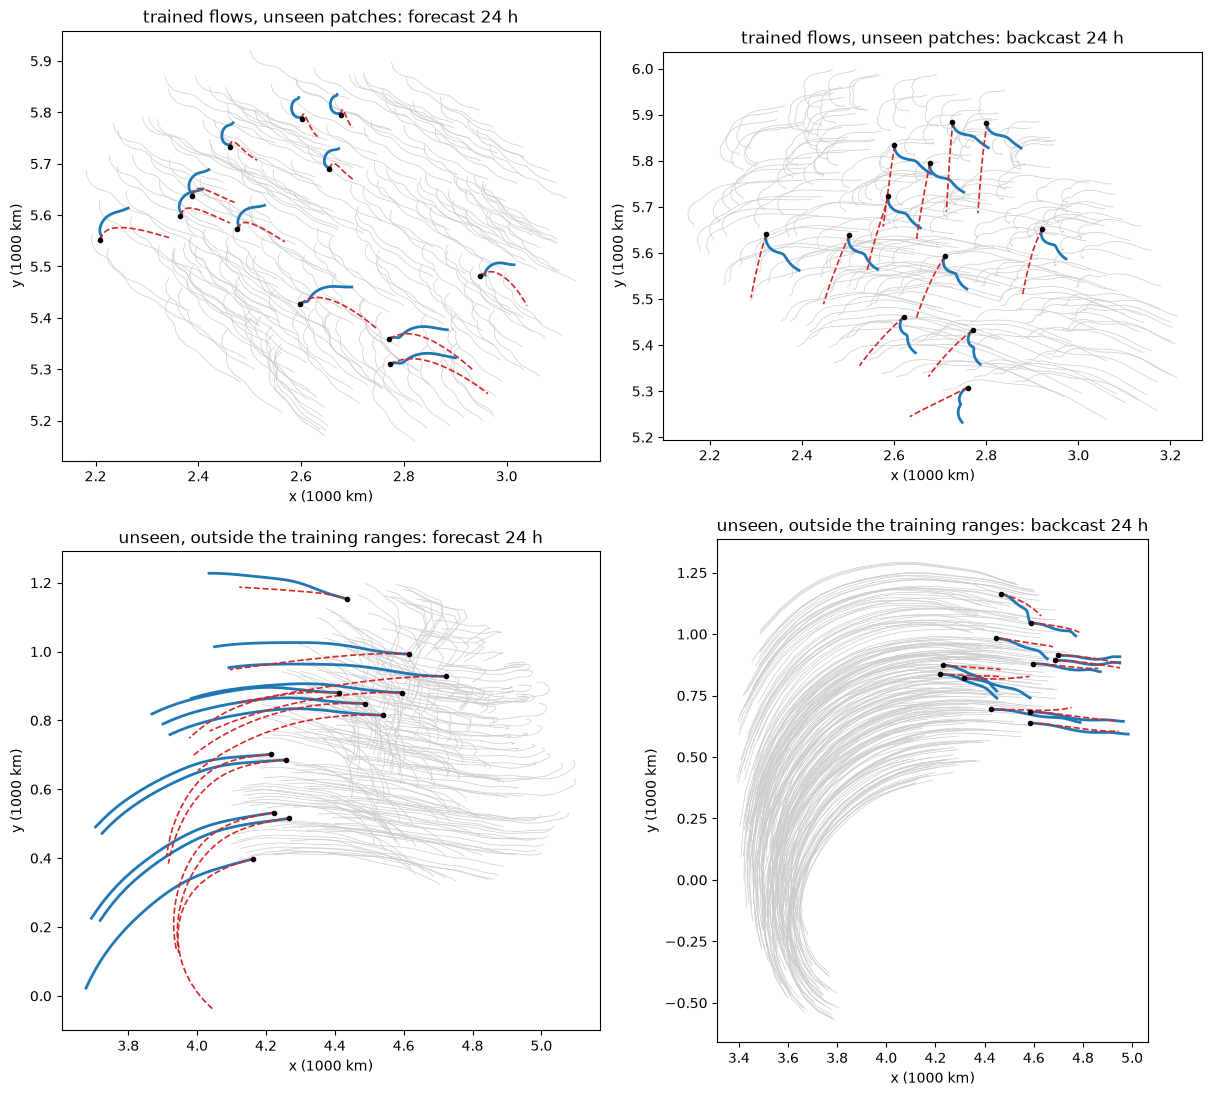

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11), layout='constrained')
for row, label in zip(axes, [cases[0][0], cases[-1][0]]):
    tok, cen, path, truth, dd = examples[(label, 'conditional KI')]
    for ax, b in zip(row, [int(np.argmax(dd > 0)), int(np.argmax(dd < 0))]):
        ctx = tok[b].reshape(SPAN_H // 3 + 1, -1, 8)[..., 1:3].numpy() * POS[0] + cen[b].numpy()
        ax.plot(ctx[:, :, 0] / 1e3, ctx[:, :, 1] / 1e3, color='0.8', lw=0.5)
        ax.plot(truth[:, b, :12, 0] / 1e3, truth[:, b, :12, 1] / 1e3, color='tab:blue', lw=2)
        ax.plot(path[:, b, :12, 0] / 1e3, path[:, b, :12, 1] / 1e3, color='tab:red', lw=1.2, ls='--')
        ax.plot(truth[0, b, :12, 0] / 1e3, truth[0, b, :12, 1] / 1e3, 'ko', ms=3)
        ax.set_aspect('equal'); ax.set(title=f"{label}: {'forecast' if dd[b] > 0 else 'backcast'} 24 h", xlabel='x (1000 km)', ylabel='y (1000 km)')
plt.show()

The vertical side of the same examples: pressure of 12 target parcels against hours from the anchor (truth blue, model red dashed), for parcels started near the surface and aloft.

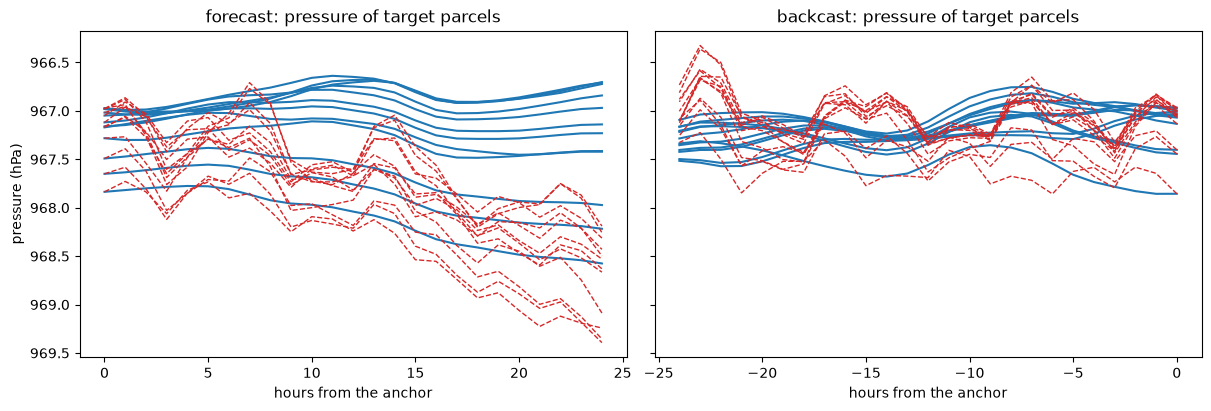

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout='constrained')
tok, cen, path, truth, dd = examples[(cases[0][0], 'conditional KI')]
for ax, b in zip(axes, [int(np.argmax(dd > 0)), int(np.argmax(dd < 0))]):
    hours = np.arange(path.shape[0]) * (1 if dd[b] > 0 else -1)
    pr = lambda z: 1000 * np.exp(-z / H_KM)
    ax.plot(hours, pr(truth[:, b, :12, 2]), color='tab:blue', lw=1.5)
    ax.plot(hours, pr(path[:, b, :12, 2]), color='tab:red', lw=1, ls='--')
    ax.set(xlabel='hours from the anchor', title=f"{'forecast' if dd[b] > 0 else 'backcast'}: pressure of target parcels")
axes[0].set_ylabel('pressure (hPa)'); axes[0].invert_yaxis()
plt.show()

## 9. Error against horizon in every case

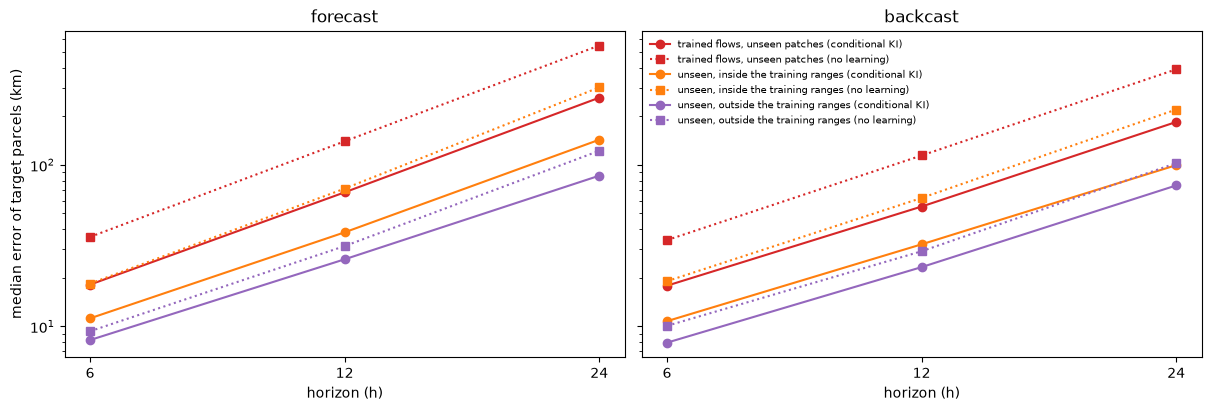

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout='constrained')
colors = dict(zip([c[0] for c in cases], ['tab:red', 'tab:orange', 'tab:purple', 'tab:brown']))
for ax, task in zip(axes, ['forecast', 'backcast']):
    for (label, mlabel), g in summary[summary.task == task].groupby(['case', 'model']):
        ax.plot(g.horizon_h, g.median_km, 'o-' if mlabel == 'conditional KI' else 's:', color=colors[label], label=f'{label} ({mlabel})')
    ax.set(xscale='log', yscale='log', xlabel='horizon (h)', title=task); ax.set_xticks(HORIZONS_H, [str(h) for h in HORIZONS_H]); ax.xaxis.set_minor_locator(plt.NullLocator())
axes[0].set_ylabel('median error of target parcels (km)'); axes[1].legend(fontsize=7, frameon=False)
plt.show()

## 10. Test movies
One movie per test case, written by `scripts/23_movies.py`: forecast (left) and backcast (right) of 12 target parcels started near 480 hPa, over relative vorticity (colour), streamfunction (contours) and wind (arrows) on that level; below, their pressure against time. Grey = the other parcels' observed tracks (the model's input), blue = truth, red dashed = model.

In [12]:
from IPython.display import Video, display
for mp4 in sorted((ROOT / 'figures/movies').glob('*.mp4')):
    print(mp4.stem.replace('_', ' '))
    display(Video(str(mp4), embed=True, width=900))

training flows unseen patch


unseen inside the training ranges


unseen outside jet 30 m s


unseen outside wavenumber 9


## 11. Optional export
Set `SAVE = True` to write the summary table.

In [13]:
SAVE = False
if SAVE:
    out = ROOT / 'outputs/notebook'; out.mkdir(parents=True, exist_ok=True)
    summary.to_csv(out / 'summary.csv', index=False)